In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle, FancyBboxPatch
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
import warnings
warnings.filterwarnings('ignore')
import io

In [2]:
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica', 'sans-serif']
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 9
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.dpi'] = 100  # For notebook display
plt.rcParams['savefig.dpi'] = 300  # For saving


In [3]:
COLORS = {
    'dmae': '#5485AB',      # Blue - Distance metrics
    'mae': '#5485AB',       # Alias for distance metrics
    'angle': '#BA4682',     # Magenta - Angular metrics
    'clash': '#E18922',     # Orange - Steric clash
    'runtime': '#CD81A8',   # Light magenta - Runtime
    'time': '#6AAAA5',      # Alias for runtime
    'target': '#007E71',    # Green - Target/optimal zones
    'ts_line': '#646363',   # Dark gray - TS reference
    'rmse' : '#007E71'
}

In [4]:
# Create output directory for png figures
import os
output_dir = 'figures_png'
os.makedirs(output_dir, exist_ok=True)
print(f"Created output directory: {output_dir}")


Created output directory: figures_png


In [5]:
# Load and parse the data
csv_hyperparameter = """images,mae,rmse,angle_error,dihedral_error,steric_clash,time,num_steps,num_samples
TS,0.143,0.458,6.156,37.228,32.947,0.153,25.0,50.0
TS,0.152,0.439,6.598,36.007,4.398,0.316,50.0,50.0
TS,0.15,0.454,6.543,36.903,52.478,0.06,10.0,50.0
TS,0.141,0.416,6.323,33.804,15.287,0.231,25.0,75.0
TS,0.156,0.515,6.582,41.536,7.612,0.064,25.0,20.0"""

csv_subsets = """images,mae,rmse,angle_error,dihedral_error,steric_clash,time,num_steps,num_samples
TS,0.156,0.515,6.582,41.536,7.612,0.064,25.0,20.0
all,0.150,0.496,6.649,38.988,1.894,0.646,25.000,20.0
0,0.294,0.726,15.28,50.424,12.338,0.064,25.0,20.0
1,0.277,0.675,14.443,46.649,2.835,0.063,25.0,20.0
2,0.255,0.63,13.321,43.804,1.967,0.064,25.0,20.0
3,0.229,0.586,11.861,43.672,15.524,0.064,25.0,20.0
4,0.184,0.542,8.875,42.516,2.679,0.065,25.0,20.0
5,0.149,0.504,6.428,39.819,6.814,0.063,25.0,20.0
6,0.206,0.518,9.486,39.712,24.029,0.065,25.0,20.0
7,0.259,0.598,11.226,43.067,52.506,0.063,25.0,20.0
8,0.301,0.654,12.603,43.82,33.595,0.064,25.0,20.0
9,0.335,0.71,13.288,46.466,29.989,0.063,25.0,20.0
0 to 3,0.29,0.704,14.85,48.354,5.08,0.246,25.0,20.0
2 to 6,0.15,0.502,6.653,40.362,2.453,0.425,25.0,20.0
6 to 9,0.21,0.544,9.596,41.302,21.61,0.249,25.0,20.0
"0,2,3,6,8",0.275,0.666,14.056,46.298,2.367,0.314,25.0,20.0
"0, 5, 9",0.186,0.549,8.611,43.993,2.54,0.185,25.0,20.0"""

csv_TS_special = """images,mae,rmse,angle_error,dihedral_error,steric_clash,time,num_steps,num_samples,batch_size,lr
TS,0.185,0.523,8.361,41.26,16.839,0.058,25.0,20.0,64,0.0005
TS,0.143,0.458,6.156,37.228,32.947,0.153,25.0,50.0,128,0.0005
TS,0.123,0.492,4.971,38.791,1.645,0.082,25.0,20.0,256,0.0005
TS,0.113,0.487,4.43,38.588,1.769,0.097,25.0,20.0,344,0.0005
TS,0.099,0.481,3.968,37.58,1.483,0.125,25.0,20.0,512,0.0005
TS,0.212,0.531,10.244,42.641,45.203,0.063,25.0,20.0,128,0.0001
TS,0.133,0.498,5.628,39.5,2.172,0.063,25.0,20.0,128,0.001"""

csv_all_weights = """images,mae,rmse,angle_error,dihedral_error,steric_clash,time,num_steps,num_samples
all-without-TS-weighting,0.159,0.47,7.507,37.801,2.511,1.527,25.0,50.0
all-with-TS-weighting,0.149,0.475,6.609,38.345,5.483,1.262,25.0,50.0"""

csv_compare_springforce = """images,mae,rmse,angle_error,dihedral_error,steric_clash,time,num_steps,num_samples,spring_force
all,0.155,0.465,7.153,37.47,3.459,1.361,25.0,50.0,True
all,0.149,0.475,6.609,38.345,5.483,1.262,25.0,50.0,False"""

csv_springforce_subsets = """images,mae,rmse,angle_error,dihedral_error,steric_clash,time,num_steps,num_samples
all,0.156,0.466,7.332,36.916,3.315,1.509,25.0,50.0
0 to 3,0.285,0.703,14.655,47.594,2.275,0.63,25.0,50.0
3 to 7,0.174,0.475,8.260,37.873,9.996,0.769,25.000,50.000
6 to 9,0.207,0.516,9.722,38.439,26.899,0.623,25.0,50.0
"0,2,3,6,8",0.28,0.681,14.461,45.695,1.657,0.777,25.0,50.0"""

csv_compare_cosine_annealing = """images,mae,rmse,angle_error,dihedral_error,steric_clash,time,num_steps,num_samples,cosine_annealing
all,0.155,0.465,7.153,37.47,3.459,1.361,25.0,50.0,False
all,0.154,0.478,7.16,38.721,2.304,1.499,25.0,50.0,True"""

csv_cos_difsteps="""images,mae,rmse,angle_error,dihedral_error,steric_clash,time,num_steps,num_samples
all-cos,0.154,0.478,7.16,38.721,2.304,1.499,25.0,50.0
all-cos,0.157,0.461,7.138,37.008,0.142,3.235,50.0,50.0"""

csv_dif_lambda = """images,mae,rmse,angle_error,dihedral_error,steric_clash,time,num_steps,num_samples,lambda
all,0.155,0.465,7.153,37.47,3.459,1.361,25.0,50.0,0.01
all,0.153,0.476,7.086,38.01,9.051,1.481,25.0,50.0,0.1
all,0.156,0.466,7.332,36.916,3.315,1.509,25.0,50.0,1.0"""

# Load into DataFrames
df_hyper = pd.read_csv(io.StringIO(csv_hyperparameter))
df_hyper.columns = ['config', 'mae', 'rmse', 'angle_error', 'dihedral_error', 'steric_clash', 'time', 'ode_steps', 'samples']

df_subsets = pd.read_csv(io.StringIO(csv_subsets))
df_subsets.columns = ['config', 'mae', 'rmse', 'angle_error', 'dihedral_error', 'steric_clash', 'time', 'ode_steps', 'samples']

# Default dataframe for subset-driven plots
df = df_subsets

# Separate by configuration type for easier analysis
ts_df = df[df['config'] == 'TS'].reset_index(drop=True)
all_df = df[df['config'] == 'all'].reset_index(drop=True)
ablation_df = df[~df['config'].isin(['TS', 'all'])].reset_index(drop=True)

# Create long-form for faceted/grouped plots
metrics = ['mae', 'rmse', 'angle_error', 'dihedral_error', 'steric_clash', 'time']
df_long = df.melt(id_vars=['config'], value_vars=metrics, var_name='metric', value_name='value')

# Load TS special experiments (with batch_size and lr variations)
df_ts_special = pd.read_csv(io.StringIO(csv_TS_special))
df_ts_special.columns = ['config', 'mae', 'rmse', 'angle_error', 'dihedral_error', 'steric_clash', 'time', 'ode_steps', 'samples', 'batch_size', 'lr']

# Load TS weighting comparison
df_all_weights = pd.read_csv(io.StringIO(csv_all_weights))
df_all_weights.columns = ['config', 'mae', 'rmse', 'angle_error', 'dihedral_error', 'steric_clash', 'time', 'ode_steps', 'samples']

df_springforce = pd.read_csv(io.StringIO(csv_compare_springforce))
df_springforce.columns = ['config', 'mae', 'rmse', 'angle_error', 'dihedral_error', 'steric_clash', 'time', 'ode_steps', 'samples', 'spring_force']
df_lambda = pd.read_csv(io.StringIO(csv_dif_lambda))
df_lambda.columns = ['config', 'mae', 'rmse', 'angle_error', 'dihedral_error', 'steric_clash', 'time', 'ode_steps', 'samples', 'lambda']
df_cosine_annealing = pd.read_csv(io.StringIO(csv_compare_cosine_annealing))
df_cosine_annealing.columns = ['config', 'mae', 'rmse', 'angle_error', 'dihedral_error', 'steric_clash', 'time', 'ode_steps', 'samples', 'cosine_annealing']
df_cos_difsteps = pd.read_csv(io.StringIO(csv_cos_difsteps))
df_cos_difsteps.columns = ['config', 'mae', 'rmse', 'angle_error', 'dihedral_error', 'steric_clash', 'time', 'ode_steps', 'samples']

print("Subset dataset shape:", df_subsets.shape)
print("Hyperparameter dataset shape:", df_hyper.shape)
print("\nTS configurations (subsets):", len(ts_df))
print("All configurations (subsets):", len(all_df))
print("Ablation configurations (subsets):", len(ablation_df))
print("\n" + "="*60)
print("TS Special (batch_size/lr) experiments:", len(df_ts_special))
print("TS Weighting comparison:", len(df_all_weights))


Subset dataset shape: (17, 9)
Hyperparameter dataset shape: (5, 9)

TS configurations (subsets): 1
All configurations (subsets): 1
Ablation configurations (subsets): 15

TS Special (batch_size/lr) experiments: 7
TS Weighting comparison: 2


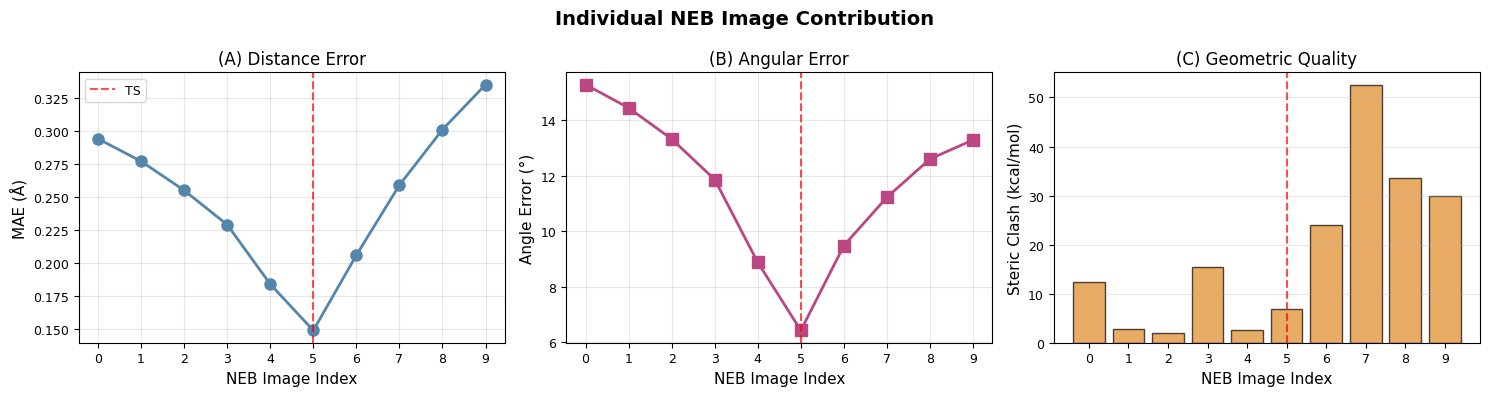

In [6]:
# ============================================================================
# FIGURE 1: Individual NEB Image Analysis
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Individual NEB Image Contribution', fontweight='bold')

# Filter single images
single_df = df[df['config'].isin(['0','1','2','3','4','5','6','7','8','9'])].copy()
single_df['img_idx'] = single_df['config'].astype(int)
single_df = single_df.sort_values('img_idx')

x = single_df['img_idx'].values

# Panel A: MAE
axes[0].plot(x, single_df['mae'], 'o-', color=COLORS['mae'], 
             linewidth=2, markersize=8)
axes[0].axvline(5, color='red', linestyle='--', alpha=0.7, label='TS')
axes[0].set_xlabel('NEB Image Index')
axes[0].set_ylabel('MAE (Å)')
axes[0].set_title('(A) Distance Error')
axes[0].grid(True, alpha=0.3)
axes[0].legend()
axes[0].set_xticks(range(10))

# Panel B: Angle Error
axes[1].plot(x, single_df['angle_error'], 's-', color=COLORS['angle'],
             linewidth=2, markersize=8)
axes[1].axvline(5, color='red', linestyle='--', alpha=0.7)
axes[1].set_xlabel('NEB Image Index')
axes[1].set_ylabel('Angle Error (°)')
axes[1].set_title('(B) Angular Error')
axes[1].grid(True, alpha=0.3)
axes[1].set_xticks(range(10))

# Panel C: Steric Clash
axes[2].bar(x, single_df['steric_clash'], color=COLORS['clash'], 
            alpha=0.7, edgecolor='black')
axes[2].axvline(5, color='red', linestyle='--', alpha=0.7)
axes[2].set_xlabel('NEB Image Index')
axes[2].set_ylabel('Steric Clash (kcal/mol)')
axes[2].set_title('(C) Geometric Quality')
axes[2].grid(True, alpha=0.3, axis='y')
axes[2].set_xticks(range(10))

plt.tight_layout()
plt.savefig(f'{output_dir}/fig1_neb_images.png', bbox_inches='tight', format='png')
plt.show()


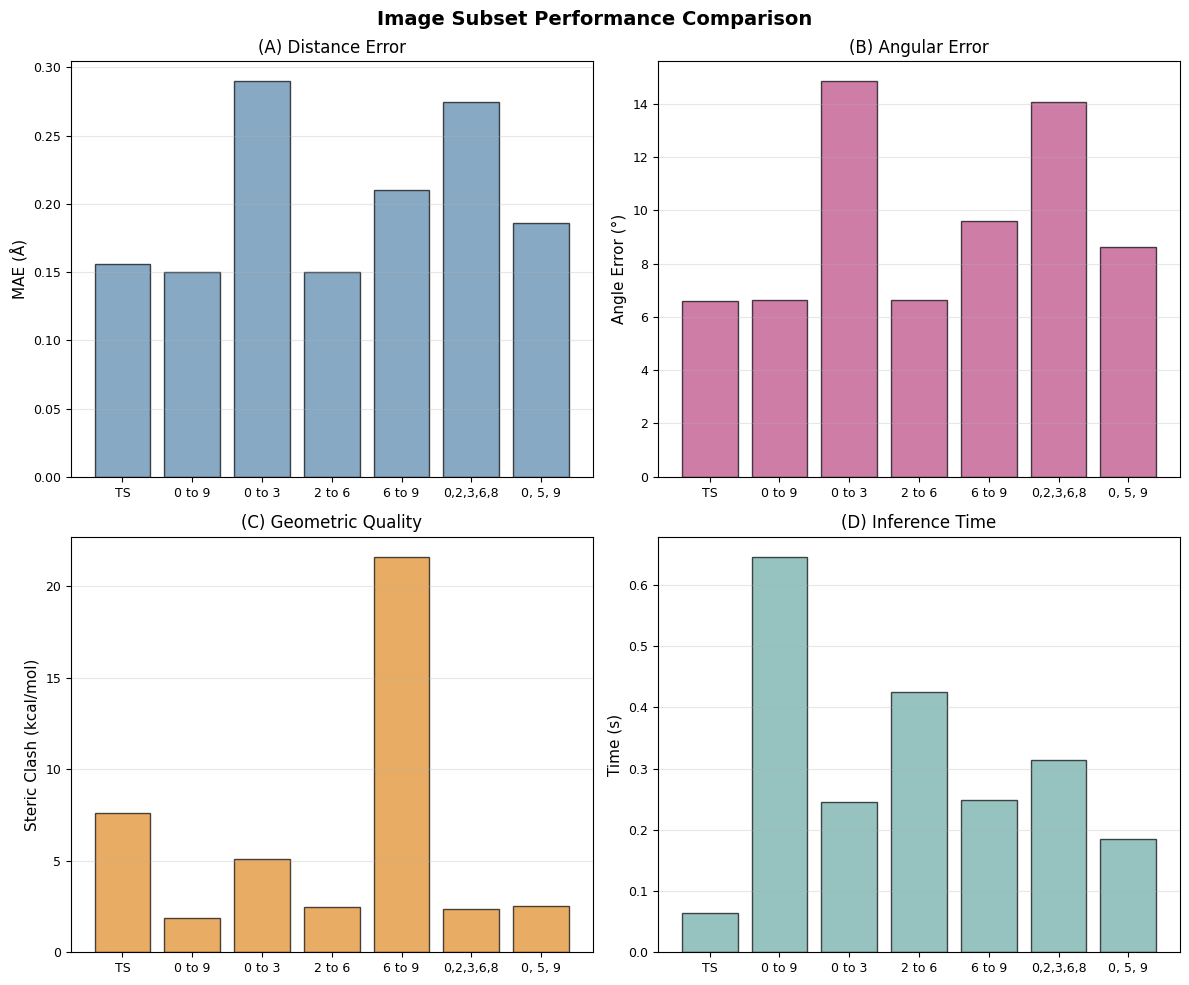

In [7]:
# ============================================================================
# FIGURE 2: Subset Comparison
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Image Subset Performance Comparison', fontweight='bold')

# Define subsets (matching config names in the CSV)
subsets = {
    'TS': df_subsets[df_subsets['config'] == 'TS'].iloc[0] if len(df_subsets[df_subsets['config'] == 'TS']) > 0 else None,
    '0 to 9': df_subsets[df_subsets['config'] == 'all'].iloc[0] if len(df_subsets[df_subsets['config'] == 'all']) > 0 else None,
    '0 to 3': df_subsets[df_subsets['config'] == '0 to 3'].iloc[0] if len(df_subsets[df_subsets['config'] == '0 to 3']) > 0 else None,
    '2 to 6': df_subsets[df_subsets['config'] == '2 to 6'].iloc[0] if len(df_subsets[df_subsets['config'] == '2 to 6']) > 0 else None,
    '6 to 9': df_subsets[df_subsets['config'] == '6 to 9'].iloc[0] if len(df_subsets[df_subsets['config'] == '6 to 9']) > 0 else None,
    '0,2,3,6,8': df_subsets[df_subsets['config'] == '0,2,3,6,8'].iloc[0] if len(df_subsets[df_subsets['config'] == '0,2,3,6,8']) > 0 else None,
    '0, 5, 9': df_subsets[df_subsets['config'] == '0, 5, 9'].iloc[0] if len(df_subsets[df_subsets['config'] == '0, 5, 9']) > 0 else None
}

subsets = {k: v for k, v in subsets.items() if v is not None}
labels = list(subsets.keys())

# Panel A: MAE
axes[0,0].bar(labels, [v['mae'] for v in subsets.values()],
               color=COLORS['mae'], alpha=0.7, edgecolor='black')
axes[0,0].set_ylabel('MAE (Å)')
axes[0,0].set_title('(A) Distance Error')
axes[0,0].grid(True, alpha=0.3, axis='y')

# Panel B: Angle Error
axes[0,1].bar(labels, [v['angle_error'] for v in subsets.values()],
               color=COLORS['angle'], alpha=0.7, edgecolor='black')
axes[0,1].set_ylabel('Angle Error (°)')
axes[0,1].set_title('(B) Angular Error')
axes[0,1].grid(True, alpha=0.3, axis='y')

# Panel C: Steric Clash
axes[1,0].bar(labels, [v['steric_clash'] for v in subsets.values()],
               color=COLORS['clash'], alpha=0.7, edgecolor='black')
axes[1,0].set_ylabel('Steric Clash (kcal/mol)')
axes[1,0].set_title('(C) Geometric Quality')
axes[1,0].grid(True, alpha=0.3, axis='y')

# Panel D: Runtime
axes[1,1].bar(labels, [v['time'] for v in subsets.values()],
               color=COLORS['time'], alpha=0.7, edgecolor='black')
axes[1,1].set_ylabel('Time (s)')
axes[1,1].set_title('(D) Inference Time')
axes[1,1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(f'{output_dir}/fig2_subsets.png', bbox_inches='tight', format='png')
plt.show()


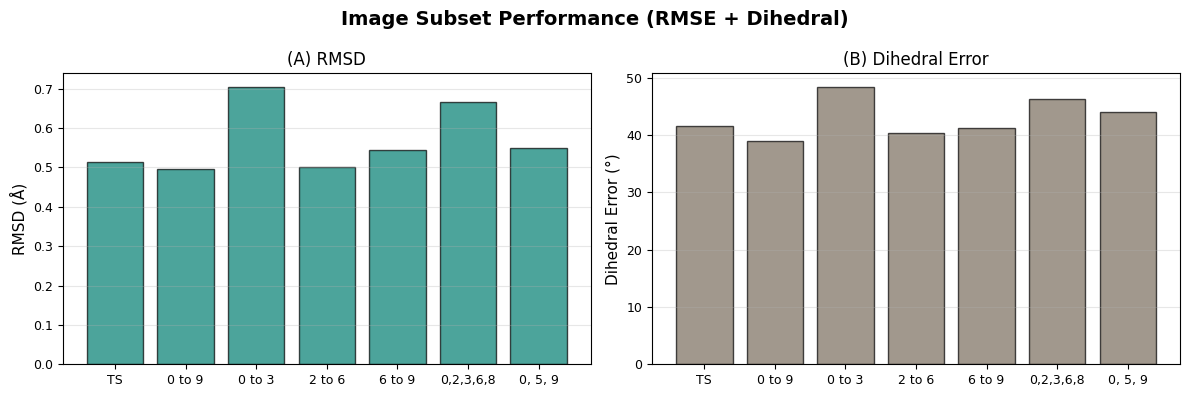

In [8]:
# ============================================================================
# FIGURE 2B: Subset Comparison (RMSE + Dihedral Error)
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Image Subset Performance (RMSE + Dihedral)', fontweight='bold')

subsets = {
    'TS': df_subsets[df_subsets['config'] == 'TS'].iloc[0] if len(df_subsets[df_subsets['config'] == 'TS']) > 0 else None,
    '0 to 9': df_subsets[df_subsets['config'] == 'all'].iloc[0] if len(df_subsets[df_subsets['config'] == 'all']) > 0 else None,
    '0 to 3': df_subsets[df_subsets['config'] == '0 to 3'].iloc[0] if len(df_subsets[df_subsets['config'] == '0 to 3']) > 0 else None,
    '2 to 6': df_subsets[df_subsets['config'] == '2 to 6'].iloc[0] if len(df_subsets[df_subsets['config'] == '2 to 6']) > 0 else None,
    '6 to 9': df_subsets[df_subsets['config'] == '6 to 9'].iloc[0] if len(df_subsets[df_subsets['config'] == '6 to 9']) > 0 else None,
    '0,2,3,6,8': df_subsets[df_subsets['config'] == '0,2,3,6,8'].iloc[0] if len(df_subsets[df_subsets['config'] == '0,2,3,6,8']) > 0 else None,
    '0, 5, 9': df_subsets[df_subsets['config'] == '0, 5, 9'].iloc[0] if len(df_subsets[df_subsets['config'] == '0, 5, 9']) > 0 else None
}

subsets = {k: v for k, v in subsets.items() if v is not None}
labels = list(subsets.keys())

# Panel A: RMSE
axes[0].bar(labels, [v['rmse'] for v in subsets.values()],
            color=COLORS['rmse'], alpha=0.7, edgecolor='black')
axes[0].set_ylabel('RMSD (Å)')
axes[0].set_title('(A) RMSD')
axes[0].grid(True, alpha=0.3, axis='y')

# Panel B: Dihedral Error
axes[1].bar(labels, [v['dihedral_error'] for v in subsets.values()],
            color='#7A6C5D', alpha=0.7, edgecolor='black')
axes[1].set_ylabel('Dihedral Error (°)')
axes[1].set_title('(B) Dihedral Error')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(f'{output_dir}/fig2b_subset_comparison.png', bbox_inches='tight', format='png')
plt.show()


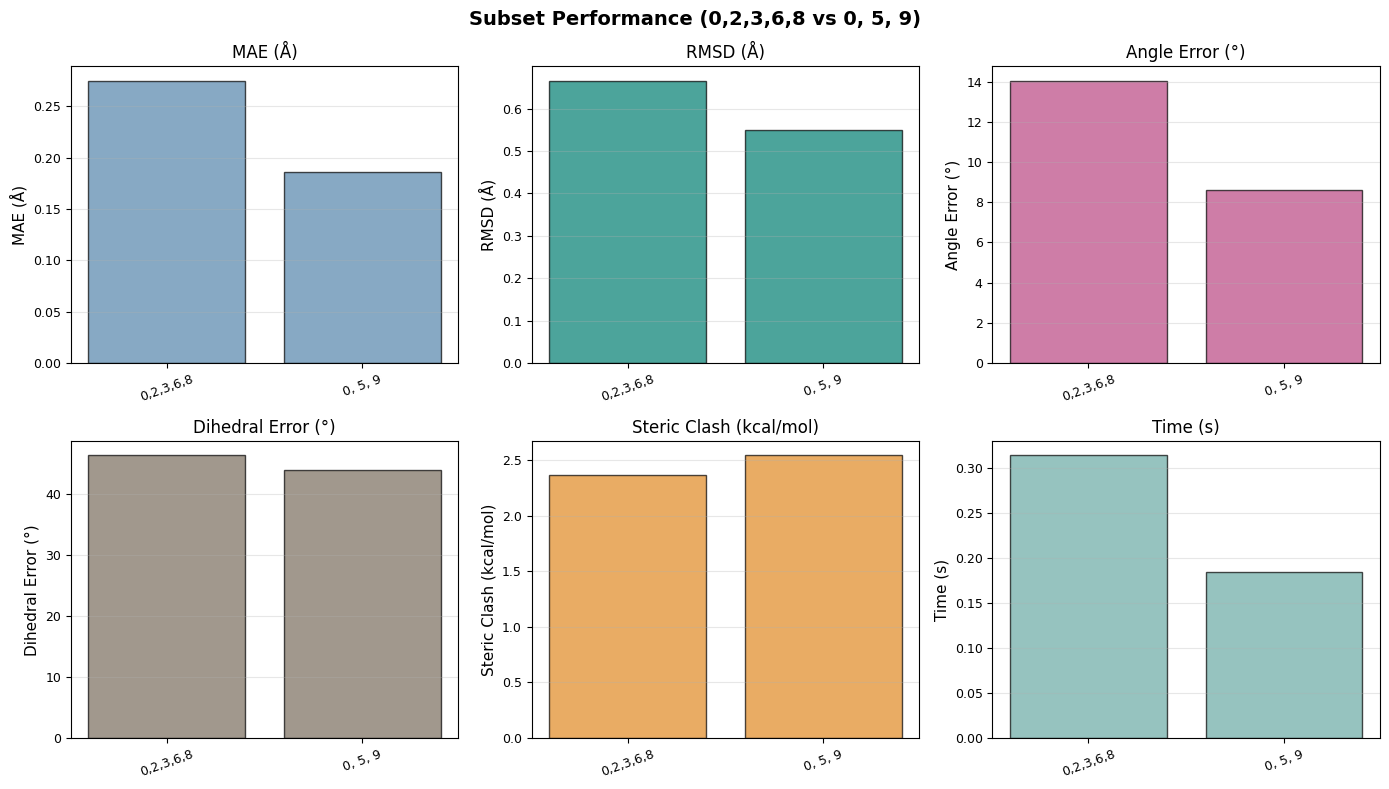

In [9]:
# ============================================================================
# FIGURE 2C: Subset Comparison for Additional Configs (All Metrics)
# ============================================================================

subset_keys = ['0,2,3,6,8', '0, 5, 9']
subset_rows = df_subsets[df_subsets['config'].isin(subset_keys)].copy()
subset_rows['config'] = pd.Categorical(subset_rows['config'], categories=subset_keys, ordered=True)
subset_rows = subset_rows.sort_values('config')

metric_panels = [
    ('mae', 'MAE (Å)', COLORS['mae']),
    ('rmse', 'RMSD (Å)', COLORS['rmse']),
    ('angle_error', 'Angle Error (°)', COLORS['angle']),
    ('dihedral_error', 'Dihedral Error (°)', '#7A6C5D'),
    ('steric_clash', 'Steric Clash (kcal/mol)', COLORS['clash']),
    ('time', 'Time (s)', COLORS['time']),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
fig.suptitle('Subset Performance (0,2,3,6,8 vs 0, 5, 9)', fontweight='bold')

for ax, (metric, label, color) in zip(axes.flatten(), metric_panels):
    ax.bar(subset_rows['config'], subset_rows[metric], color=color, alpha=0.7, edgecolor='black')
    ax.set_title(label)
    ax.set_ylabel(label)
    ax.grid(True, alpha=0.3, axis='y')
    ax.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()


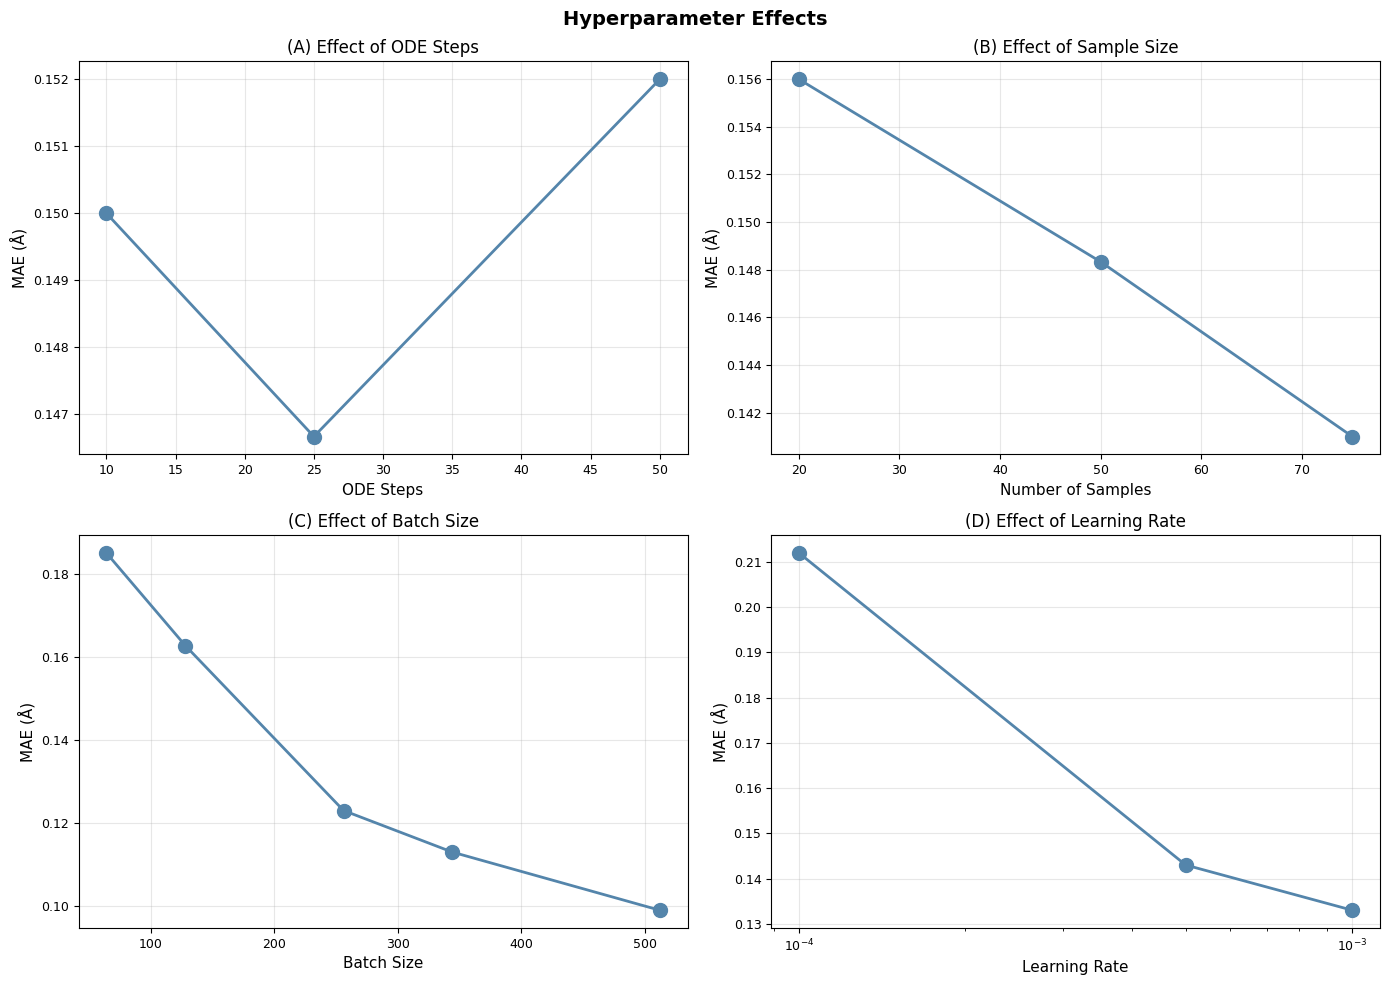

In [10]:
# ============================================================================
# FIGURE 3: Hyperparameters (ODE Steps, Samples, Batch Size, Learning Rate)
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Hyperparameter Effects', fontweight='bold')

# Panel A: ODE Steps
ts_hyper_df = df_hyper.copy()
ode_grouped = ts_hyper_df.groupby('ode_steps')['mae'].mean().sort_index()

axes[0,0].plot(ode_grouped.index, ode_grouped.values, 'o-', 
             color=COLORS['mae'], linewidth=2, markersize=10)
axes[0,0].set_xlabel('ODE Steps')
axes[0,0].set_ylabel('MAE (Å)')
axes[0,0].set_title('(A) Effect of ODE Steps')
axes[0,0].grid(True, alpha=0.3)

# Panel B: Sample Size
sample_grouped = ts_hyper_df.groupby('samples')['mae'].mean().sort_index()

axes[0,1].plot(sample_grouped.index, sample_grouped.values, 'o-',
             color=COLORS['mae'], linewidth=2, markersize=10)
axes[0,1].set_xlabel('Number of Samples')
axes[0,1].set_ylabel('MAE (Å)')
axes[0,1].set_title('(B) Effect of Sample Size')
axes[0,1].grid(True, alpha=0.3)

# Panel C: Batch Size (using df_ts_special)
batch_grouped = df_ts_special.groupby('batch_size')['mae'].mean().sort_index()

axes[1,0].plot(batch_grouped.index, batch_grouped.values, 'o-', 
             color=COLORS['mae'], linewidth=2, markersize=10)
axes[1,0].set_xlabel('Batch Size')
axes[1,0].set_ylabel('MAE (Å)')
axes[1,0].set_title('(C) Effect of Batch Size')
axes[1,0].grid(True, alpha=0.3)

# Panel D: Learning Rate (using df_ts_special)
# Filter for consistent batch_size (128) to isolate lr effect
lr_df = df_ts_special[df_ts_special['batch_size'] == 128].copy()
lr_grouped = lr_df.groupby('lr')['mae'].mean().sort_index()

axes[1,1].plot(lr_grouped.index, lr_grouped.values, 'o-',
             color=COLORS['mae'], linewidth=2, markersize=10)
axes[1,1].set_xlabel('Learning Rate')
axes[1,1].set_ylabel('MAE (Å)')
axes[1,1].set_title('(D) Effect of Learning Rate')
axes[1,1].set_xscale('log')  # Log scale for learning rate
axes[1,1].grid(True, alpha=0.3)


plt.tight_layout()
plt.savefig(f'{output_dir}/fig3_hyperparameters.png', bbox_inches='tight', format='png')
plt.show()


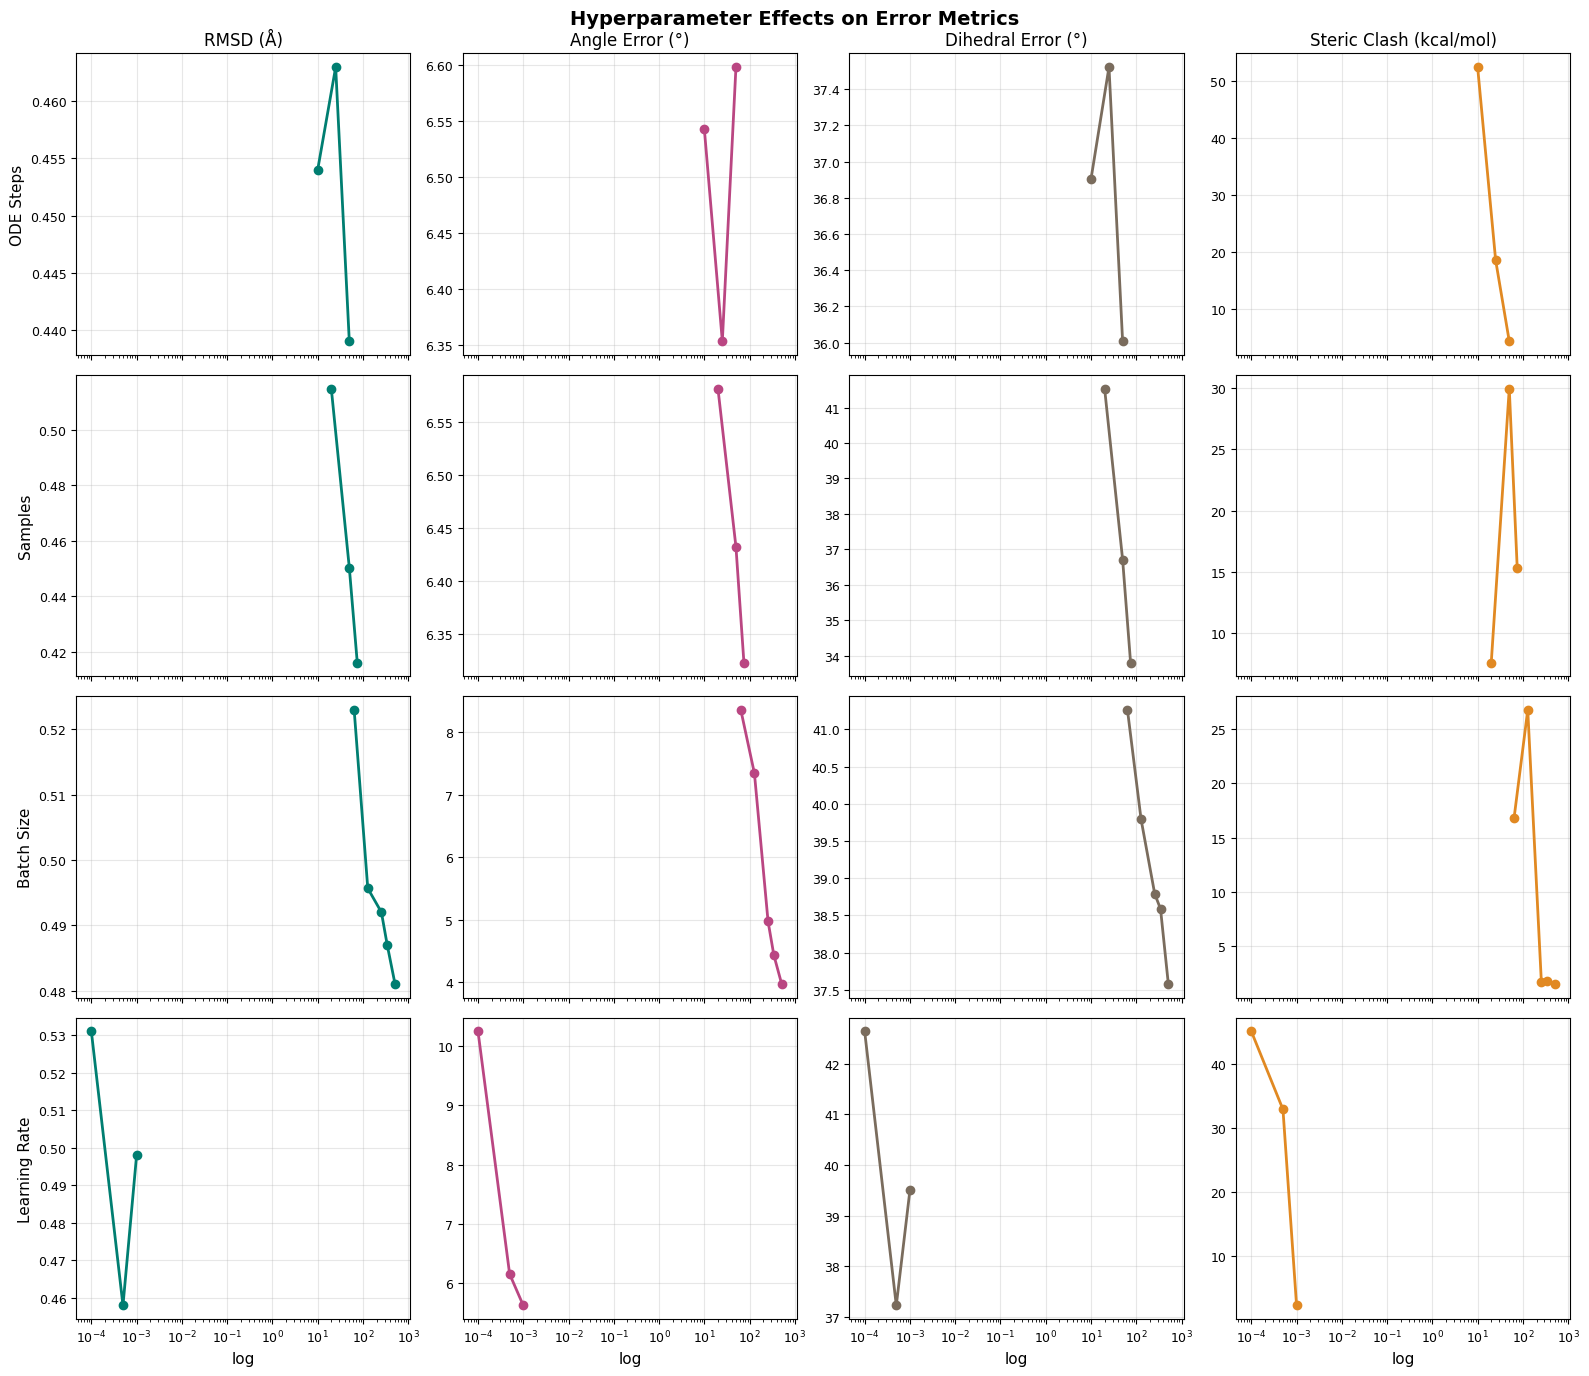

In [11]:
# ============================================================================
# FIGURE 3B: Hyperparameters (RMSE, Angle, Dihedral, Steric)
# ============================================================================

metric_info = [
    ('rmse', 'RMSD (Å)', COLORS['rmse']),
    ('angle_error', 'Angle Error (°)', COLORS['angle']),
    ('dihedral_error', 'Dihedral Error (°)', '#7A6C5D'),
    ('steric_clash', 'Steric Clash (kcal/mol)', COLORS['clash']),
]

ts_hyper_df = df_hyper.copy()
lr_df = df_ts_special[df_ts_special['batch_size'] == 128].copy()

hyperparams = [
    {'name': 'ODE Steps', 'df': ts_hyper_df, 'x': 'ode_steps', 'x_label': 'ODE Steps', 'xscale': 'linear'},
    {'name': 'Samples', 'df': ts_hyper_df, 'x': 'samples', 'x_label': 'Number of Samples', 'xscale': 'linear'},
    {'name': 'Batch Size', 'df': df_ts_special, 'x': 'batch_size', 'x_label': 'Batch Size', 'xscale': 'linear'},
    {'name': 'Learning Rate', 'df': lr_df, 'x': 'lr', 'x_label': 'Learning Rate', 'xscale': 'log'},
]

fig, axes = plt.subplots(4, 4, figsize=(16, 14), sharex='col')
fig.suptitle('Hyperparameter Effects on Error Metrics', fontweight='bold')

for r, hp in enumerate(hyperparams):
    grouped = hp['df'].groupby(hp['x'])[[m[0] for m in metric_info]].mean().sort_index()
    for c, (metric, label, color) in enumerate(metric_info):
        ax = axes[r, c]
        ax.plot(grouped.index, grouped[metric].values, 'o-', color=color, linewidth=2, markersize=6)
        if r == 0:
            ax.set_title(label)
        if r == len(hyperparams) - 1:
            ax.set_xlabel(hp['xscale'])
        if c == 0:
            ax.set_ylabel(hp['name'])
        ax.grid(True, alpha=0.3)
        if hp['xscale'] == 'log':
            ax.set_xscale('log')

plt.tight_layout()
plt.savefig(f'{output_dir}/fig3b_hyperparameters_all.png', bbox_inches='tight', format='png')
plt.show()


In [12]:
# ============================================================================
# SUMMARY STATISTICS
# ============================================================================

print("\n" + "="*80)
print("KEY STATISTICS")
print("="*80)

ts_baseline = df[df['config'] == 'TS'].iloc[0]
print(f"\nBaseline (TS-Only):")
print(f"  MAE: {ts_baseline['mae']:.3f} Å")
print(f"  Angle Error: {ts_baseline['angle_error']:.2f}°")
print(f"  Time: {ts_baseline['time']:.3f} s")

best_single = single_df.nsmallest(1, 'mae').iloc[0]
print(f"\nBest Single Image:")
print(f"  Image {int(best_single['img_idx'])}: MAE = {best_single['mae']:.3f} Å")

if 'Central (2-6)' in subsets:
    central = subsets['Central (2-6)']
    print(f"\nBest Subset (Central 2-6):")
    print(f"  MAE: {central['mae']:.3f} Å")
    print(f"  Angle Error: {central['angle_error']:.2f}°")
    print(f"  Time: {central['time']:.3f} s")

print("\n" + "="*80)
print("✓ All figures saved!")
print("="*80)








KEY STATISTICS

Baseline (TS-Only):
  MAE: 0.156 Å
  Angle Error: 6.58°
  Time: 0.064 s

Best Single Image:
  Image 5: MAE = 0.149 Å

✓ All figures saved!


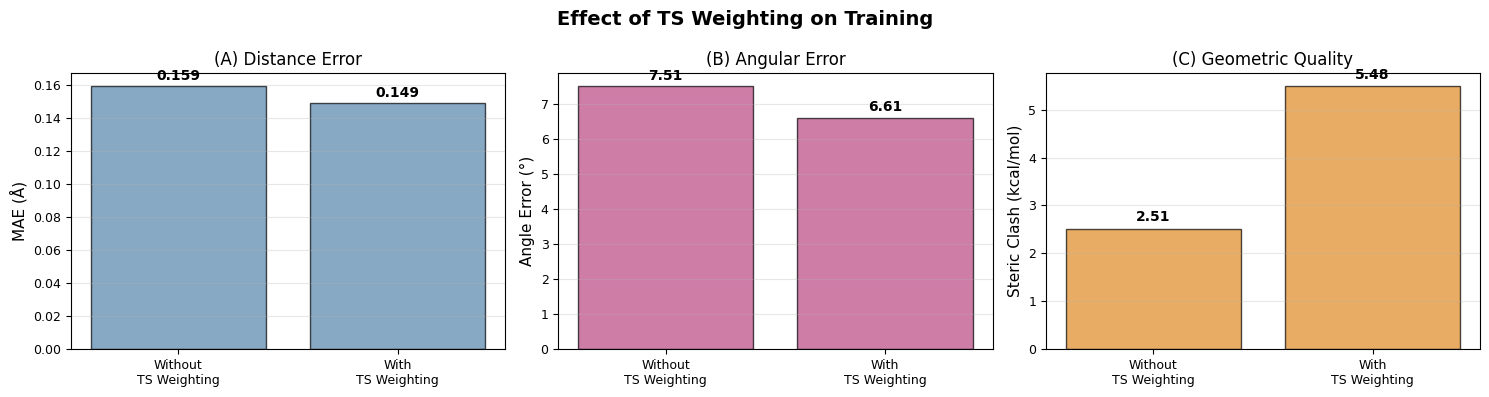


TS WEIGHTING IMPACT

Improvement with TS weighting:
  MAE: 6.3% reduction
  Angle Error: 12.0% reduction
  Steric Clash: -118.4% reduction


In [13]:
# ============================================================================
# FIGURE 5: TS Weighting Comparison
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Effect of TS Weighting on Training', fontweight='bold')

# Prepare data
configs = df_all_weights['config'].tolist()
labels = ['Without\nTS Weighting', 'With\nTS Weighting']

# Panel A: MAE Comparison
mae_values = df_all_weights['mae'].tolist()
axes[0].bar(labels, mae_values, color=[COLORS['mae'], COLORS['mae']], 
            alpha=0.7, edgecolor='black')
axes[0].set_ylabel('MAE (Å)')
axes[0].set_title('(A) Distance Error')
axes[0].grid(True, alpha=0.3, axis='y')
# Add values on bars
for i, v in enumerate(mae_values):
    axes[0].text(i, v + 0.002, f'{v:.3f}', ha='center', va='bottom', fontweight='bold')

# Panel B: Angle Error Comparison
angle_values = df_all_weights['angle_error'].tolist()
axes[1].bar(labels, angle_values, color=[COLORS['angle'], COLORS['angle']], 
            alpha=0.7, edgecolor='black')
axes[1].set_ylabel('Angle Error (°)')
axes[1].set_title('(B) Angular Error')
axes[1].grid(True, alpha=0.3, axis='y')
# Add values on bars
for i, v in enumerate(angle_values):
    axes[1].text(i, v + 0.1, f'{v:.2f}', ha='center', va='bottom', fontweight='bold')

# Panel C: Steric Clash Comparison
clash_values = df_all_weights['steric_clash'].tolist()
axes[2].bar(labels, clash_values, color=[COLORS['clash'], COLORS['clash']], 
            alpha=0.7, edgecolor='black')
axes[2].set_ylabel('Steric Clash (kcal/mol)')
axes[2].set_title('(C) Geometric Quality')
axes[2].grid(True, alpha=0.3, axis='y')
# Add values on bars
for i, v in enumerate(clash_values):
    axes[2].text(i, v + 0.1, f'{v:.2f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig(f'{output_dir}/fig5_ts_weighting.png', bbox_inches='tight', format='png')
plt.show()

# Print improvement statistics
print("\n" + "="*80)
print("TS WEIGHTING IMPACT")
print("="*80)
mae_improvement = (df_all_weights.iloc[0]['mae'] - df_all_weights.iloc[1]['mae']) / df_all_weights.iloc[0]['mae'] * 100
angle_improvement = (df_all_weights.iloc[0]['angle_error'] - df_all_weights.iloc[1]['angle_error']) / df_all_weights.iloc[0]['angle_error'] * 100
geometric_improvement = (df_all_weights.iloc[0]['steric_clash'] - df_all_weights.iloc[1]['steric_clash']) / df_all_weights.iloc[0]['steric_clash'] * 100
print(f"\nImprovement with TS weighting:")
print(f"  MAE: {mae_improvement:.1f}% reduction")
print(f"  Angle Error: {angle_improvement:.1f}% reduction")
print(f"  Steric Clash: {geometric_improvement:.1f}% reduction")
print("="*80)


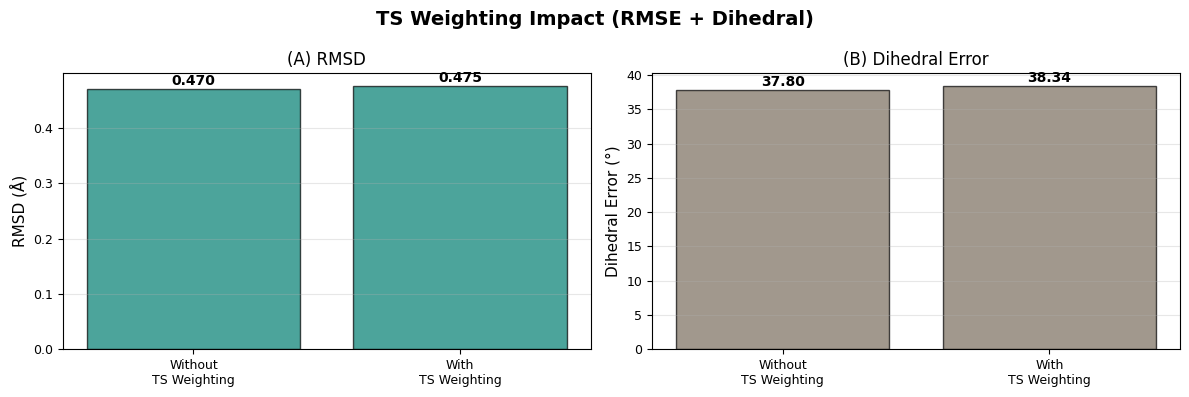

In [14]:
# ============================================================================
# FIGURE 5B: TS Weighting (RMSE + Dihedral Error)
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('TS Weighting Impact (RMSE + Dihedral)', fontweight='bold')

labels = ['Without\nTS Weighting', 'With\nTS Weighting']

# Panel A: RMSE
rmse_values = df_all_weights['rmse'].tolist()
axes[0].bar(labels, rmse_values, color=COLORS['rmse'], alpha=0.7, edgecolor='black')
axes[0].set_ylabel('RMSD (Å)')
axes[0].set_title('(A) RMSD')
axes[0].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(rmse_values):
    axes[0].text(i, v + 0.002, f'{v:.3f}', ha='center', va='bottom', fontweight='bold')

# Panel B: Dihedral Error
dihedral_values = df_all_weights['dihedral_error'].tolist()
axes[1].bar(labels, dihedral_values, color='#7A6C5D', alpha=0.7, edgecolor='black')
axes[1].set_ylabel('Dihedral Error (°)')
axes[1].set_title('(B) Dihedral Error')
axes[1].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(dihedral_values):
    axes[1].text(i, v + 0.2, f'{v:.2f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


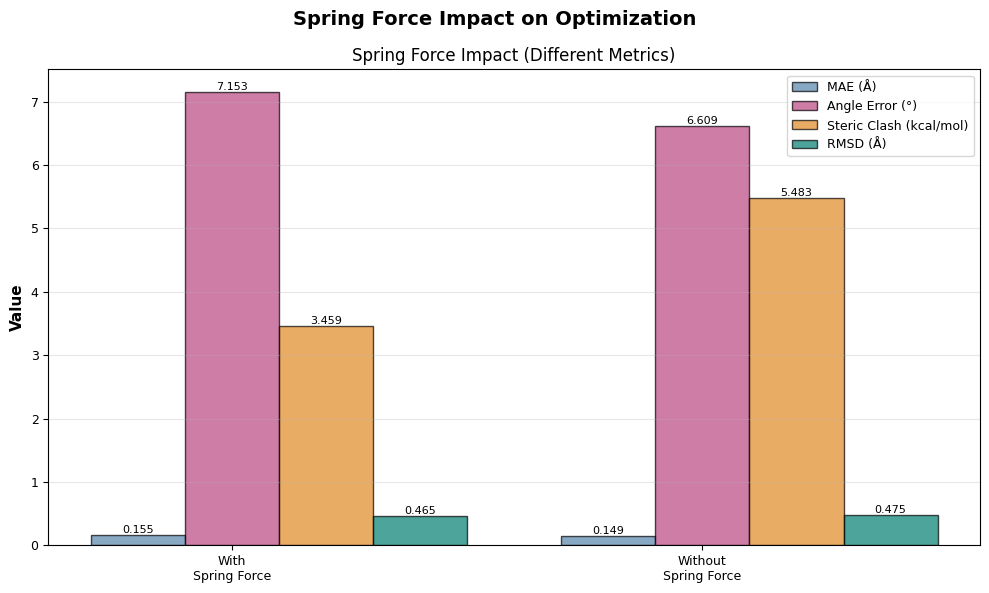

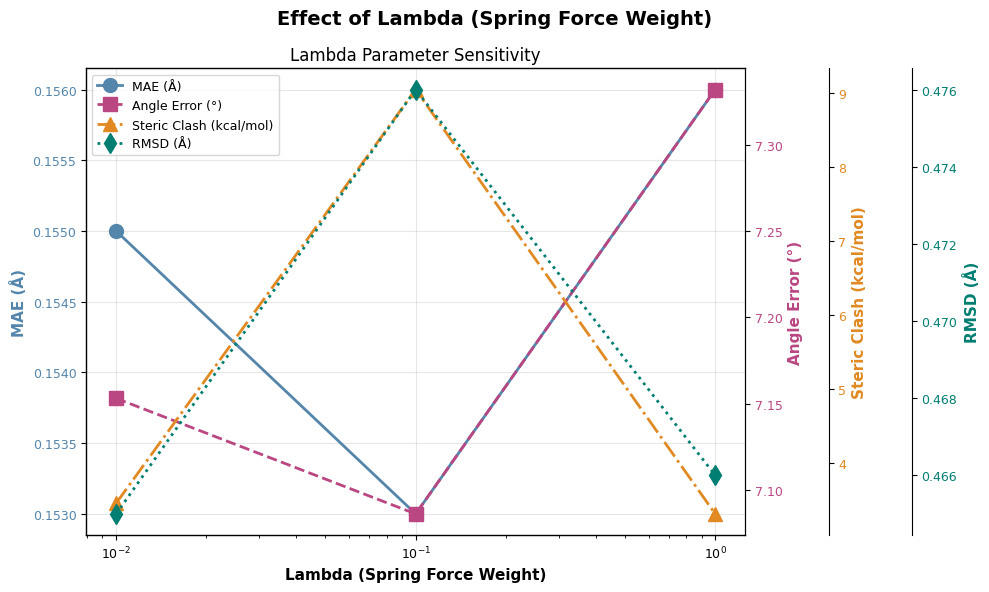


SPRING FORCE ANALYSIS

Improvement WITH Spring Force (vs without):
  MAE: -4.0% degradation
  Angle Error: -8.2% degradation

Best Lambda Value: 0.1
  MAE: 0.153 Å
  Angle Error: 7.09°


In [15]:
# ============================================================================
# FIGURE 6: Spring Force and Lambda Effects
# ============================================================================

# Panel A: With vs Without Spring Force
fig1, ax1 = plt.subplots(1, 1, figsize=(10, 6))
fig1.suptitle('Spring Force Impact on Optimization', fontweight='bold')

springforce_labels = ['With\nSpring Force', 'Without\nSpring Force']
springforce_mae = df_springforce['mae'].tolist()
springforce_angle = df_springforce['angle_error'].tolist()
springforce_steric = df_springforce['steric_clash'].tolist()
springforce_rmse = df_springforce['rmse'].tolist()

x_pos = np.arange(len(springforce_labels))
width = 0.2

bars1 = ax1.bar(x_pos - width, springforce_mae, width, label='MAE (Å)', 
                color=COLORS['mae'], alpha=0.7, edgecolor='black')
bars2 = ax1.bar(x_pos, springforce_angle, width, label='Angle Error (°)',
                color=COLORS['angle'], alpha=0.7, edgecolor='black')
bars3 = ax1.bar(x_pos + width, springforce_steric, width, label='Steric Clash (kcal/mol)',
                color=COLORS['clash'], alpha=0.7, edgecolor='black')
bars4 = ax1.bar(x_pos + 2*width, springforce_rmse, width, label='RMSD (Å)',
                color=COLORS['rmse'], alpha=0.7, edgecolor='black')

ax1.set_ylabel('Value', fontweight='bold')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(springforce_labels)
ax1.set_title('Spring Force Impact (Different Metrics)')
ax1.legend()
ax1.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bars in [bars1, bars2, bars3, bars4]:
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig(f'{output_dir}/fig6a_springforce.png', bbox_inches='tight', format='png')
plt.show()

# Panel B: Different Lambda Values
fig2, ax2 = plt.subplots(1, 1, figsize=(10, 6))
fig2.suptitle('Effect of Lambda (Spring Force Weight)', fontweight='bold')

lambda_vals = df_lambda['lambda'].tolist()
lambda_mae = df_lambda['mae'].tolist()
lambda_angle = df_lambda['angle_error'].tolist()
lambda_clash = df_lambda['steric_clash'].tolist()
lambda_rmsd = df_lambda['rmse'].tolist()

ax2.plot(lambda_vals, lambda_mae, 'o-', color=COLORS['mae'], 
         linewidth=2, markersize=10, label='MAE (Å)')
ax2_twin1 = ax2.twinx()
ax2_twin1.plot(lambda_vals, lambda_angle, 's--', color=COLORS['angle'],
               linewidth=2, markersize=10, label='Angle Error (°)')
ax2_twin2 = ax2.twinx()
ax2_twin2.spines['right'].set_position(('outward', 60))
ax2_twin2.plot(lambda_vals, lambda_clash, '^-.', color=COLORS['clash'],
               linewidth=2, markersize=10, label='Steric Clash (kcal/mol)')
ax2_twin3 = ax2.twinx()
ax2_twin3.spines['right'].set_position(('outward', 120))
ax2_twin3.plot(lambda_vals, lambda_rmsd, 'd:', color=COLORS['rmse'],
               linewidth=2, markersize=10, label='RMSD (Å)')

ax2.set_xlabel('Lambda (Spring Force Weight)', fontweight='bold')
ax2.set_ylabel('MAE (Å)', color=COLORS['mae'], fontweight='bold')
ax2_twin1.set_ylabel('Angle Error (°)', color=COLORS['angle'], fontweight='bold')
ax2_twin2.set_ylabel('Steric Clash (kcal/mol)', color=COLORS['clash'], fontweight='bold')
ax2_twin3.set_ylabel('RMSD (Å)', color=COLORS['rmse'], fontweight='bold')
ax2.set_title('Lambda Parameter Sensitivity')
ax2.set_xscale('log')
ax2.grid(True, alpha=0.3)
ax2.tick_params(axis='y', labelcolor=COLORS['mae'])
ax2_twin1.tick_params(axis='y', labelcolor=COLORS['angle'])
ax2_twin2.tick_params(axis='y', labelcolor=COLORS['clash'])
ax2_twin3.tick_params(axis='y', labelcolor=COLORS['rmse'])

# Combine legends
lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_twin1.get_legend_handles_labels()
lines3, labels3 = ax2_twin2.get_legend_handles_labels()
lines4, labels4 = ax2_twin3.get_legend_handles_labels()
ax2.legend(lines1 + lines2 + lines3 + lines4, labels1 + labels2 + labels3 + labels4, loc='best')

plt.tight_layout()
plt.savefig(f'{output_dir}/fig6b_lambda.png', bbox_inches='tight', format='png')
plt.show()

print("\n" + "="*80)
print("SPRING FORCE ANALYSIS")
print("="*80)
mae_improvement_sf = (df_springforce.iloc[1]['mae'] - df_springforce.iloc[0]['mae']) / df_springforce.iloc[1]['mae'] * 100
angle_improvement_sf = (df_springforce.iloc[1]['angle_error'] - df_springforce.iloc[0]['angle_error']) / df_springforce.iloc[1]['angle_error'] * 100
print(f"\nImprovement WITH Spring Force (vs without):")
print(f"  MAE: {mae_improvement_sf:.1f}% {'improvement' if mae_improvement_sf > 0 else 'degradation'}")
print(f"  Angle Error: {angle_improvement_sf:.1f}% {'improvement' if angle_improvement_sf > 0 else 'degradation'}")

best_lambda_idx = df_lambda['mae'].idxmin()
best_lambda = df_lambda.loc[best_lambda_idx]
print(f"\nBest Lambda Value: {best_lambda['lambda']}")
print(f"  MAE: {best_lambda['mae']:.3f} Å")
print(f"  Angle Error: {best_lambda['angle_error']:.2f}°")
print("="*80)

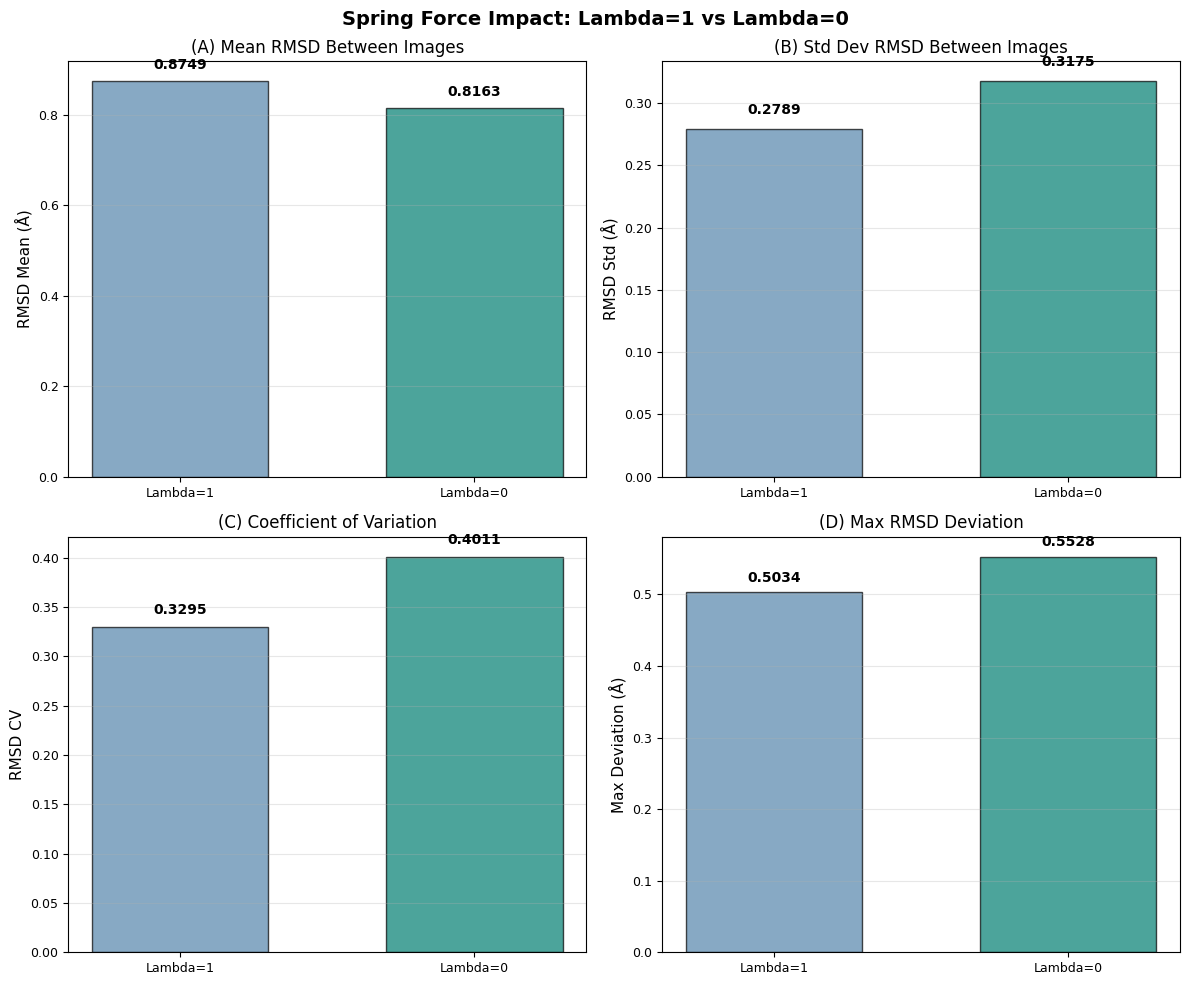


LAMBDA COMPARISON (SPACING & DEVIATION ANALYSIS)

Lambda=1 (With Spring Force):
  Mean RMSD Between Images: 0.8749 Å
  Std Dev: 0.2789 Å
  CV: 0.3295

Lambda=0 (Without Spring Force):
  Mean RMSD Between Images: 0.8163 Å
  Std Dev: 0.3175 Å
  CV: 0.4011

Impact of Spring Force (Lambda=1):
  Mean RMSD: 7.2% higher (more uniform spacing)
  Std Dev: -12.2% higher


In [16]:
# ============================================================================
# FIGURE 6C: Lambda Comparison (Spacing and Deviation Metrics)
# ============================================================================

# Data for lambda=1 vs lambda=0 comparison
lambda_comparison_data = {
    'config': ['Lambda=1', 'Lambda=0'],
    'rmsd_mean_btw_images': [0.8749, 0.8163],
    'rmsd_std_btw_images': [0.2789, 0.3175],
    'rmsd_cv_btw_images': [0.3295, 0.4011],
    'rmsd_max_deviation': [0.5034, 0.5528]
}

df_lambda_comp = pd.DataFrame(lambda_comparison_data)

fig3, axes = plt.subplots(2, 2, figsize=(12, 10))
fig3.suptitle('Spring Force Impact: Lambda=1 vs Lambda=0', fontweight='bold')

labels = df_lambda_comp['config'].tolist()
x_pos = np.arange(len(labels))
width = 0.6

# Panel A: RMSD Mean Between Images
axes[0,0].bar(x_pos, df_lambda_comp['rmsd_mean_btw_images'], width,
              color=[COLORS['mae'], COLORS['rmse']], alpha=0.7, edgecolor='black')
axes[0,0].set_ylabel('RMSD Mean (Å)')
axes[0,0].set_title('(A) Mean RMSD Between Images')
axes[0,0].set_xticks(x_pos)
axes[0,0].set_xticklabels(labels)
axes[0,0].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(df_lambda_comp['rmsd_mean_btw_images']):
    axes[0,0].text(i, v + 0.02, f'{v:.4f}', ha='center', va='bottom', fontweight='bold')

# Panel B: RMSD Std Between Images
axes[0,1].bar(x_pos, df_lambda_comp['rmsd_std_btw_images'], width,
              color=[COLORS['mae'], COLORS['rmse']], alpha=0.7, edgecolor='black')
axes[0,1].set_ylabel('RMSD Std (Å)')
axes[0,1].set_title('(B) Std Dev RMSD Between Images')
axes[0,1].set_xticks(x_pos)
axes[0,1].set_xticklabels(labels)
axes[0,1].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(df_lambda_comp['rmsd_std_btw_images']):
    axes[0,1].text(i, v + 0.01, f'{v:.4f}', ha='center', va='bottom', fontweight='bold')

# Panel C: RMSD CV Between Images
axes[1,0].bar(x_pos, df_lambda_comp['rmsd_cv_btw_images'], width,
              color=[COLORS['mae'], COLORS['rmse']], alpha=0.7, edgecolor='black')
axes[1,0].set_ylabel('RMSD CV')
axes[1,0].set_title('(C) Coefficient of Variation')
axes[1,0].set_xticks(x_pos)
axes[1,0].set_xticklabels(labels)
axes[1,0].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(df_lambda_comp['rmsd_cv_btw_images']):
    axes[1,0].text(i, v + 0.01, f'{v:.4f}', ha='center', va='bottom', fontweight='bold')

# Panel D: RMSD Max Deviation
axes[1,1].bar(x_pos, df_lambda_comp['rmsd_max_deviation'], width,
              color=[COLORS['mae'], COLORS['rmse']], alpha=0.7, edgecolor='black')
axes[1,1].set_ylabel('Max Deviation (Å)')
axes[1,1].set_title('(D) Max RMSD Deviation')
axes[1,1].set_xticks(x_pos)
axes[1,1].set_xticklabels(labels)
axes[1,1].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(df_lambda_comp['rmsd_max_deviation']):
    axes[1,1].text(i, v + 0.01, f'{v:.4f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig(f'{output_dir}/fig6c_lambda_spacing_comparison.png', bbox_inches='tight', format='png')
plt.show()

print("\n" + "="*80)
print("LAMBDA COMPARISON (SPACING & DEVIATION ANALYSIS)")
print("="*80)
print(f"\nLambda=1 (With Spring Force):")
print(f"  Mean RMSD Between Images: {df_lambda_comp.iloc[0]['rmsd_mean_btw_images']:.4f} Å")
print(f"  Std Dev: {df_lambda_comp.iloc[0]['rmsd_std_btw_images']:.4f} Å")
print(f"  CV: {df_lambda_comp.iloc[0]['rmsd_cv_btw_images']:.4f}")

print(f"\nLambda=0 (Without Spring Force):")
print(f"  Mean RMSD Between Images: {df_lambda_comp.iloc[1]['rmsd_mean_btw_images']:.4f} Å")
print(f"  Std Dev: {df_lambda_comp.iloc[1]['rmsd_std_btw_images']:.4f} Å")
print(f"  CV: {df_lambda_comp.iloc[1]['rmsd_cv_btw_images']:.4f}")

improvement_rmsd = (df_lambda_comp.iloc[1]['rmsd_mean_btw_images'] - df_lambda_comp.iloc[0]['rmsd_mean_btw_images']) / df_lambda_comp.iloc[1]['rmsd_mean_btw_images'] * 100
improvement_std = (df_lambda_comp.iloc[1]['rmsd_std_btw_images'] - df_lambda_comp.iloc[0]['rmsd_std_btw_images']) / df_lambda_comp.iloc[1]['rmsd_std_btw_images'] * 100

print(f"\nImpact of Spring Force (Lambda=1):")
print(f"  Mean RMSD: {-improvement_rmsd:.1f}% {'higher' if improvement_rmsd < 0 else 'lower'} (more uniform spacing)")
print(f"  Std Dev: {-improvement_std:.1f}% {'lower' if improvement_std < 0 else 'higher'}")
print("="*80)


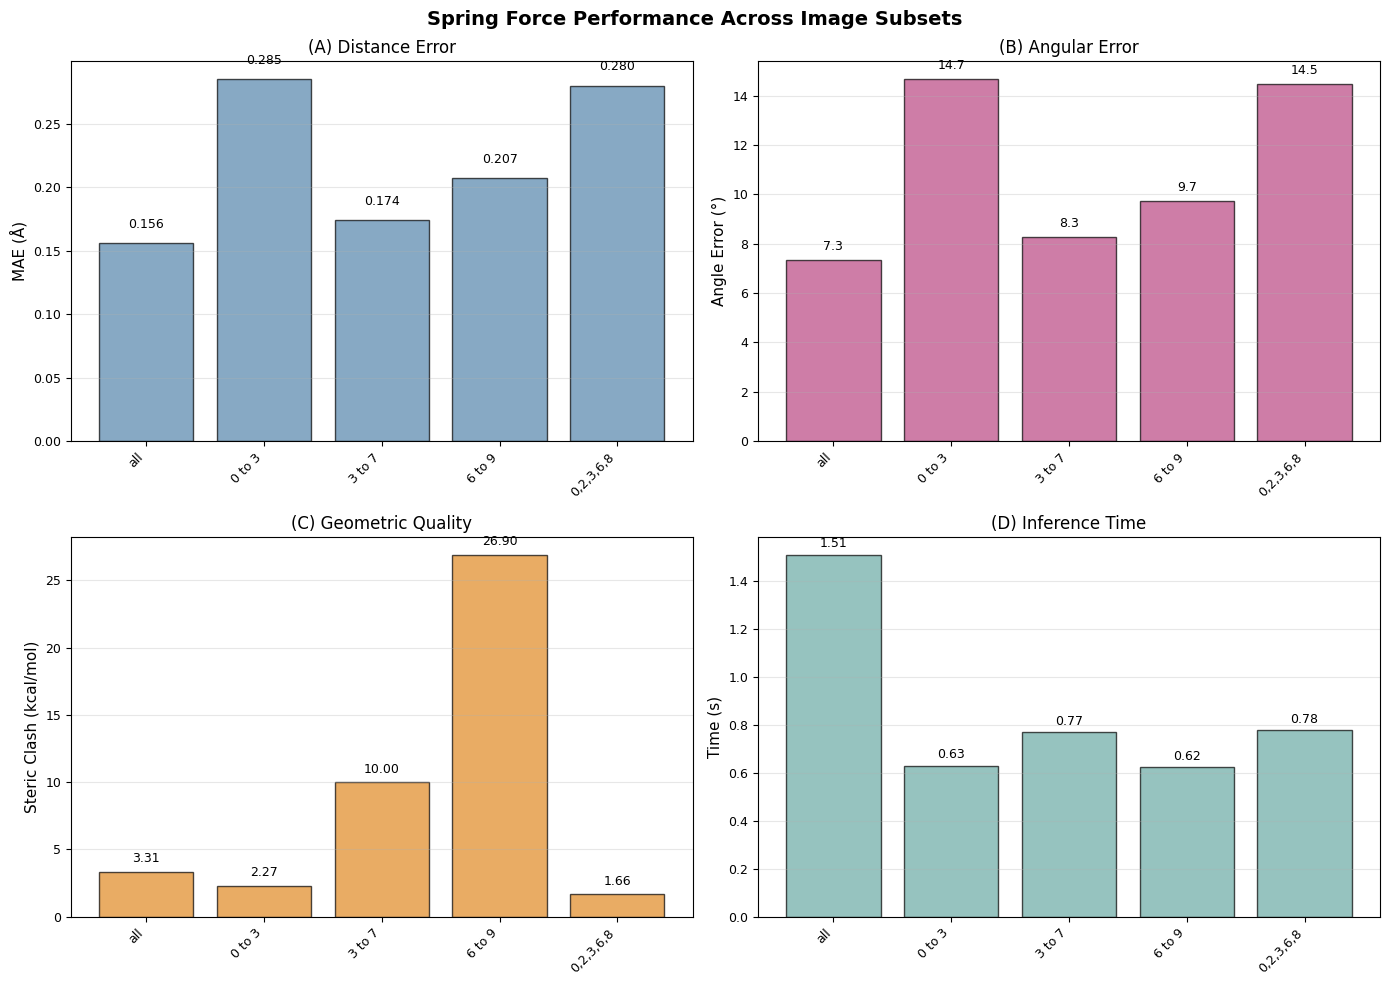


SPRING FORCE SUBSETS ANALYSIS

Best Subset with Spring Force: all
  MAE: 0.156 Å
  Angle Error: 7.33°
  Steric Clash: 3.31 kcal/mol
  Time: 1.509 s


In [17]:
# ============================================================================
# FIGURE 7: Spring Force with Different Image Subsets
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Spring Force Performance Across Image Subsets', fontweight='bold')

# Load spring force subsets data
df_sf_subsets = pd.read_csv(io.StringIO(csv_springforce_subsets))
df_sf_subsets.columns = ['config', 'mae', 'rmse', 'angle_error', 'dihedral_error', 'steric_clash', 'time', 'ode_steps', 'samples']

subset_labels = df_sf_subsets['config'].tolist()
x_pos = np.arange(len(subset_labels))

# Panel A: MAE across subsets
axes[0,0].bar(x_pos, df_sf_subsets['mae'], color=COLORS['mae'], 
              alpha=0.7, edgecolor='black')
axes[0,0].set_ylabel('MAE (Å)')
axes[0,0].set_title('(A) Distance Error')
axes[0,0].set_xticks(x_pos)
axes[0,0].set_xticklabels(subset_labels, rotation=45, ha='right')
axes[0,0].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(df_sf_subsets['mae']):
    axes[0,0].text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontsize=9)

# Panel B: Angle Error across subsets
axes[0,1].bar(x_pos, df_sf_subsets['angle_error'], color=COLORS['angle'],
              alpha=0.7, edgecolor='black')
axes[0,1].set_ylabel('Angle Error (°)')
axes[0,1].set_title('(B) Angular Error')
axes[0,1].set_xticks(x_pos)
axes[0,1].set_xticklabels(subset_labels, rotation=45, ha='right')
axes[0,1].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(df_sf_subsets['angle_error']):
    axes[0,1].text(i, v + 0.3, f'{v:.1f}', ha='center', va='bottom', fontsize=9)

# Panel C: Steric Clash across subsets
axes[1,0].bar(x_pos, df_sf_subsets['steric_clash'], color=COLORS['clash'],
              alpha=0.7, edgecolor='black')
axes[1,0].set_ylabel('Steric Clash (kcal/mol)')
axes[1,0].set_title('(C) Geometric Quality')
axes[1,0].set_xticks(x_pos)
axes[1,0].set_xticklabels(subset_labels, rotation=45, ha='right')
axes[1,0].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(df_sf_subsets['steric_clash']):
    axes[1,0].text(i, v + 0.5, f'{v:.2f}', ha='center', va='bottom', fontsize=9)

# Panel D: Inference Time across subsets
axes[1,1].bar(x_pos, df_sf_subsets['time'], color=COLORS['time'],
              alpha=0.7, edgecolor='black')
axes[1,1].set_ylabel('Time (s)')
axes[1,1].set_title('(D) Inference Time')
axes[1,1].set_xticks(x_pos)
axes[1,1].set_xticklabels(subset_labels, rotation=45, ha='right')
axes[1,1].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(df_sf_subsets['time']):
    axes[1,1].text(i, v + 0.02, f'{v:.2f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(f'{output_dir}/fig7_springforce_subsets.png', bbox_inches='tight', format='png')
plt.show()

print("\n" + "="*80)
print("SPRING FORCE SUBSETS ANALYSIS")
print("="*80)
best_subset_idx = df_sf_subsets['mae'].idxmin()
best_subset = df_sf_subsets.loc[best_subset_idx]
print(f"\nBest Subset with Spring Force: {best_subset['config']}")
print(f"  MAE: {best_subset['mae']:.3f} Å")
print(f"  Angle Error: {best_subset['angle_error']:.2f}°")
print(f"  Steric Clash: {best_subset['steric_clash']:.2f} kcal/mol")
print(f"  Time: {best_subset['time']:.3f} s")
print("="*80)

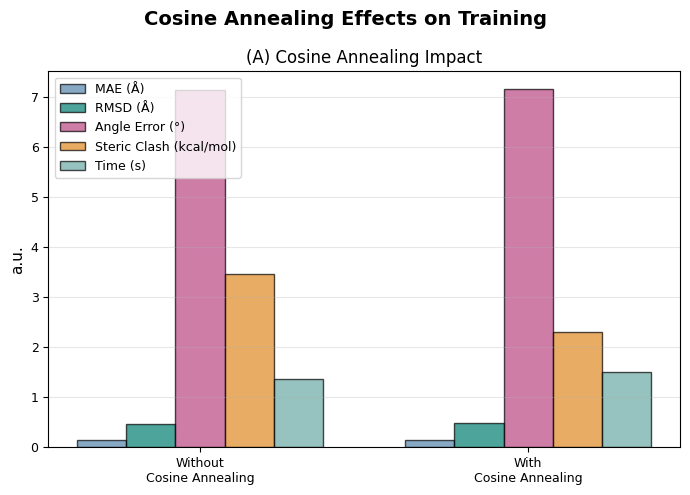

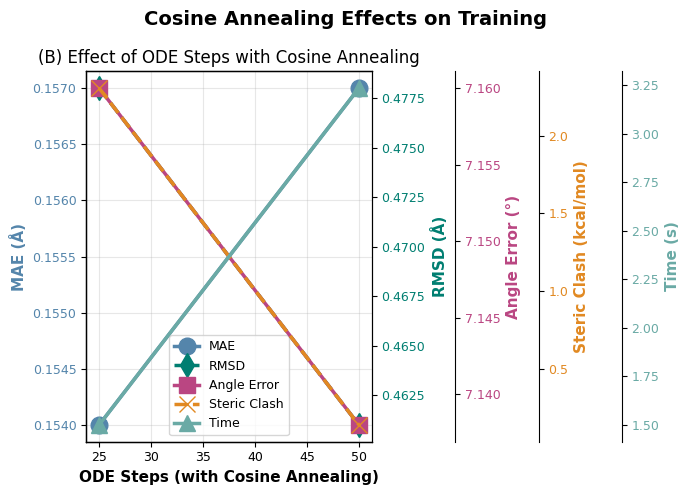


COSINE ANNEALING ANALYSIS

Impact of Cosine Annealing:
  MAE: 0.6% improvement
  Angle Error: -0.1% degradation
  Time: 10.1% increase

Best Configuration with Cosine Annealing:
  ODE Steps: 25
  MAE: 0.154 Å
  Angle Error: 7.16°
  Time: 1.499 s


In [18]:
# ============================================================================
# FIGURE 8: Cosine Annealing Effects (split panels)
# ============================================================================

# --- Panel A: With vs Without Cosine Annealing ---
fig_a, ax_a = plt.subplots(1, 1, figsize=(7, 5))
fig_a.suptitle('Cosine Annealing Effects on Training', fontweight='bold')

cosine_labels = ['Without\nCosine Annealing', 'With\nCosine Annealing']
cosine_mae = df_cosine_annealing['mae'].tolist()
cosine_rmse = df_cosine_annealing['rmse'].tolist()
cosine_angle = df_cosine_annealing['angle_error'].tolist()
cosine_steric = df_cosine_annealing['steric_clash'].tolist()
cosine_time = df_cosine_annealing['time'].tolist()

x_pos = np.arange(len(cosine_labels))
width = 0.15

ax_a.bar(x_pos - 2*width, cosine_mae, width, label='MAE (Å)',
         color=COLORS['mae'], alpha=0.7, edgecolor='black')
ax_a.bar(x_pos - width, cosine_rmse, width, label='RMSD (Å)',
         color=COLORS['rmse'], alpha=0.7, edgecolor='black')
ax_a.bar(x_pos, cosine_angle, width, label='Angle Error (°)',
         color=COLORS['angle'], alpha=0.7, edgecolor='black')
ax_a.bar(x_pos + width, cosine_steric, width, label='Steric Clash (kcal/mol)',
         color=COLORS['clash'], alpha=0.7, edgecolor='black')
ax_a.bar(x_pos + 2 * width, cosine_time, width, label='Time (s)',
         color=COLORS['time'], alpha=0.7, edgecolor='black')

ax_a.set_ylabel('a.u.')
ax_a.set_title('(A) Cosine Annealing Impact')
ax_a.set_xticks(x_pos)
ax_a.set_xticklabels(cosine_labels)
ax_a.legend(loc='upper left', fontsize=9)
ax_a.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(f'{output_dir}/fig8a_cosine_annealing.png', bbox_inches='tight', format='png')
plt.show()

# --- Panel B: Different ODE Steps with Cosine Annealing ---
fig_b, ax_b = plt.subplots(1, 1, figsize=(7, 5))
fig_b.suptitle('Cosine Annealing Effects on Training', fontweight='bold')

steps = df_cos_difsteps['ode_steps'].tolist()
steps_mae = df_cos_difsteps['mae'].tolist()
steps_rmse = df_cos_difsteps['rmse'].tolist()
steps_angle = df_cos_difsteps['angle_error'].tolist()
steps_steric = df_cos_difsteps['steric_clash'].tolist()
steps_time = df_cos_difsteps['time'].tolist()

ax_rmse = ax_b.twinx()
ax_angle = ax_b.twinx()
ax_steric = ax_b.twinx()
ax_time = ax_b.twinx()
ax_angle.spines['right'].set_position(('outward', 60))
ax_steric.spines['right'].set_position(('outward', 120))
ax_time.spines['right'].set_position(('outward', 180))

line1 = ax_b.plot(steps, steps_mae, 'o-', color=COLORS['mae'],
                  linewidth=2.5, markersize=12, label='MAE')
line2 = ax_rmse.plot(steps, steps_rmse, 'd--', color=COLORS['rmse'],
                     linewidth=2.5, markersize=12, label='RMSD')
line3 = ax_angle.plot(steps, steps_angle, 's-', color=COLORS['angle'],
                      linewidth=2.5, markersize=12, label='Angle Error')
line4 = ax_steric.plot(steps, steps_steric, 'x--', color=COLORS['clash'],
                       linewidth=2.5, markersize=12, label='Steric Clash')
line5 = ax_time.plot(steps, steps_time, '^-', color=COLORS['time'],
                     linewidth=2.5, markersize=12, label='Time')

ax_b.set_xlabel('ODE Steps (with Cosine Annealing)', fontweight='bold')
ax_b.set_ylabel('MAE (Å)', color=COLORS['mae'], fontweight='bold')
ax_rmse.set_ylabel('RMSD (Å)', color=COLORS['rmse'], fontweight='bold')
ax_angle.set_ylabel('Angle Error (°)', color=COLORS['angle'], fontweight='bold')
ax_steric.set_ylabel('Steric Clash (kcal/mol)', color=COLORS['clash'], fontweight='bold')
ax_time.set_ylabel('Time (s)', color=COLORS['time'], fontweight='bold')
ax_b.set_title('(B) Effect of ODE Steps with Cosine Annealing')
ax_b.grid(True, alpha=0.3)
ax_b.tick_params(axis='y', labelcolor=COLORS['mae'])
ax_rmse.tick_params(axis='y', labelcolor=COLORS['rmse'])
ax_angle.tick_params(axis='y', labelcolor=COLORS['angle'])
ax_steric.tick_params(axis='y', labelcolor=COLORS['clash'])
ax_time.tick_params(axis='y', labelcolor=COLORS['time'])

lines = line1 + line2 + line3 + line4 + line5
labels = [l.get_label() for l in lines]
ax_b.legend(lines, labels, loc='lower center', fontsize=9)

plt.tight_layout()
plt.savefig(f'{output_dir}/fig8b_cosine_annealing_steps.png', bbox_inches='tight', format='png')
plt.show()

print("\n" + "=" * 80)
print("COSINE ANNEALING ANALYSIS")
print("=" * 80)
mae_improvement_ca = (df_cosine_annealing.iloc[0]['mae'] - df_cosine_annealing.iloc[1]['mae']) / df_cosine_annealing.iloc[0]['mae'] * 100
angle_improvement_ca = (df_cosine_annealing.iloc[0]['angle_error'] - df_cosine_annealing.iloc[1]['angle_error']) / df_cosine_annealing.iloc[0]['angle_error'] * 100
time_change_ca = (df_cosine_annealing.iloc[1]['time'] - df_cosine_annealing.iloc[0]['time']) / df_cosine_annealing.iloc[0]['time'] * 100

print(f"\nImpact of Cosine Annealing:")
print(f"  MAE: {mae_improvement_ca:.1f}% {'improvement' if mae_improvement_ca > 0 else 'degradation'}")
print(f"  Angle Error: {angle_improvement_ca:.1f}% {'improvement' if angle_improvement_ca > 0 else 'degradation'}")
print(f"  Time: {time_change_ca:.1f}% {'increase' if time_change_ca > 0 else 'decrease'}")

best_steps_idx = df_cos_difsteps['mae'].idxmin()
best_steps = df_cos_difsteps.loc[best_steps_idx]
print(f"\nBest Configuration with Cosine Annealing:")
print(f"  ODE Steps: {int(best_steps['ode_steps'])}")
print(f"  MAE: {best_steps['mae']:.3f} Å")
print(f"  Angle Error: {best_steps['angle_error']:.2f}°")
print(f"  Time: {best_steps['time']:.3f} s")
print("=" * 80)
